In [18]:
import torch
from torch import nn, optim
from torch.utils.data import DataLoader
from torchvision import transforms, datasets
# datasets:  이미지 파일과 정답 레이블을 관리하고, 모델 학습에 사용할 수 있는 Dataset 객체를 생성하는 모듈
# transforms: 모델이 학습할 수 있도록 이미지의 크기, 자료형, 차원, 픽셀값 등을 변환하는 모듈입니다. 데이터 증강(Data Augmentation)에도 사용됩니다.
import matplotlib.pyplot as plt
import numpy as np
import os
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [19]:
# function 파일 오류 수정 후 런타임을 재시작하지 않고 수정내용을 반영하는 방법
# import importlib
# import multiclass_functions
# importlib.reload(multiclass_functions)

from multiclass_functions import *

In [20]:
os.makedirs('results', exist_ok=True)

In [21]:
BATCH_SIZE = 32
LR = 1e-3
EPOCH = 5
criterion = nn.CrossEntropyLoss()

# 기존 모델을 사용 :False, 새로운 모델 생성 : True
new_model_train=False

model_type = 'CNN_deep'

dataset = 'MNIST'
save_model_path = f'results/{model_type}_{dataset}.pt'

In [22]:
transform = transforms.ToTensor()

train_DS = datasets.MNIST(root='data', train=True, download=True, transform=transform)
test_DS = datasets.MNIST(root='data', train=False, download=True, transform=transform)

train_DL = DataLoader(train_DS, batch_size = BATCH_SIZE, shuffle=True)
test_DL = DataLoader(test_DS, batch_size= BATCH_SIZE, shuffle=True)

['0 - zero', '1 - one', '2 - two', '3 - three', '4 - four', '5 - five', '6 - six', '7 - seven', '8 - eight', '9 - nine']
{'0 - zero': 0, '1 - one': 1, '2 - two': 2, '3 - three': 3, '4 - four': 4, '5 - five': 5, '6 - six': 6, '7 - seven': 7, '8 - eight': 8, '9 - nine': 9}
0 - zero


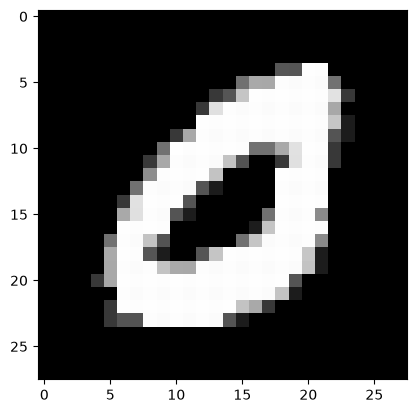

In [23]:
print(test_DS.classes)
print(test_DS.class_to_idx)

x_batch, y_batch = next(iter(train_DL))

plt.imshow(x_batch[0,0], cmap='gray')   # x_batch는 2차원
print(test_DS.classes[y_batch[0]])      # y_batch는 2차원

In [24]:
class CNN(nn.Module):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.conv1 = nn.Sequential(
            nn.Conv2d(1,8,3, padding=1),    # input(32,1,28,28)
            nn.BatchNorm2d(8),
            nn.ReLU()
            )
        self.maxpool1 = nn.MaxPool2d(2)
        self.conv2 = nn.Sequential(
            nn.Conv2d(8,16,3),
            nn.BatchNorm2d(16),
            nn.ReLU()
            )
        self.maxpool2 = nn.MaxPool2d(2)
        self.conv3 = nn.Sequential(
            nn.Conv2d(16,32,3),
            nn.BatchNorm2d(32),
            nn.ReLU()
            )
        self.maxpool3 = nn.MaxPool2d(2)
        self.fc = nn.Linear(32*2*2, 10)

    def forward(self, x, *args, **kwargs):
        x = self.conv1(x)
        x = self.maxpool1(x)
        x = self.conv2(x)
        x = self.maxpool2(x)
        x = self.conv3(x)
        x = self.maxpool3(x)
        x = torch.flatten(x, start_dim=1)
        x = self.fc(x)
        return x


class CNN_deep(nn.Module):
    def __init__(self, *args, **kwargs):
        super().__init__(*args,**kwargs)
        self.conv_block1 = nn.Sequential(nn.Conv2d(1,32,3, padding=1),
                                         nn.BatchNorm2d(32),
                                         nn.ReLU(),
                                         nn.Conv2d(32,32,3, padding=1),
                                         nn.BatchNorm2d(32),
                                         nn.ReLU())
        self.maxpool1 = nn.MaxPool2d(2)

        self.conv_block2 = nn.Sequential(nn.Conv2d(32,64,3, padding=1),
                                         nn.BatchNorm2d(64),
                                         nn.ReLU(),
                                         nn.Conv2d(64,64,3, padding=1),
                                         nn.BatchNorm2d(64),
                                         nn.ReLU(),
                                         nn.Conv2d(64,64,3, padding=1),
                                         nn.BatchNorm2d(64),
                                         nn.ReLU())

        self.maxpool2 = nn.MaxPool2d(2)
        
        self.conv_block3 = nn.Sequential(nn.Conv2d(64,128,3, padding=1),
                                         nn.BatchNorm2d(128),
                                         nn.ReLU(),
                                         nn.Conv2d(128,128,3, padding=1),
                                         nn.BatchNorm2d(128),
                                         nn.ReLU(),
                                         nn.Conv2d(128,128,3, padding=1),
                                         nn.BatchNorm2d(128),
                                         nn.ReLU())

        self.maxpool3 = nn.MaxPool2d(2)

        self.fc = nn.Sequential(nn.Linear(128*3*3,512),
                                nn.ReLU(),
                                nn.Linear(512, 10))

    def forward(self, x, *args, **kwargs):
        x = self.conv_block1(x)
        x = self.maxpool1(x)
        x = self.conv_block2(x)
        x = self.maxpool2(x)
        x = self.conv_block3(x)
        x = self.maxpool3(x)
        x = torch.flatten(x, start_dim=1)
        x = self.fc(x)
        return x

In [25]:
features, labels = next(iter(train_DL))

print(f"입력 데이터 shape: {features.shape}")
print(f"정답 레이블 shape: {labels.shape}")

입력 데이터 shape: torch.Size([32, 1, 28, 28])
정답 레이블 shape: torch.Size([32])


In [26]:
model = globals()[model_type]().to(device)

model.eval()
with torch.no_grad():
    print(model(x_batch.to(device)).shape)

torch.Size([32, 10])


In [27]:
if new_model_train:
    optimizer = optim.Adam(model.parameters(), lr=LR)
    loss_history = Train(model, train_DL, criterion, optimizer, EPOCH)

    torch.save(model, save_model_path)

    plt.figure()
    plt.plot(range(1, EPOCH+1), loss_history)
    plt.xlabel('EPOCH')
    plt.ylabel('LOSS')
    plt.title('TRAIN LOSS')
    plt.grid()

In [28]:
load_model = torch.load(save_model_path, map_location= device, weights_only=False)

In [29]:
Test(load_model, test_DL)
print(count_params(load_model))

Test accuracy : 9938 / 10000 (99.4 %)
1067690


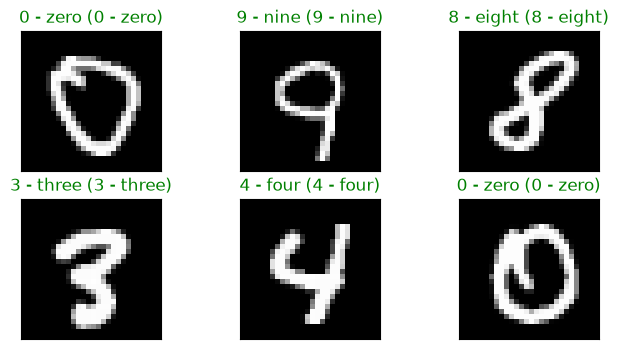

In [30]:
Test_plot(load_model, test_DL)

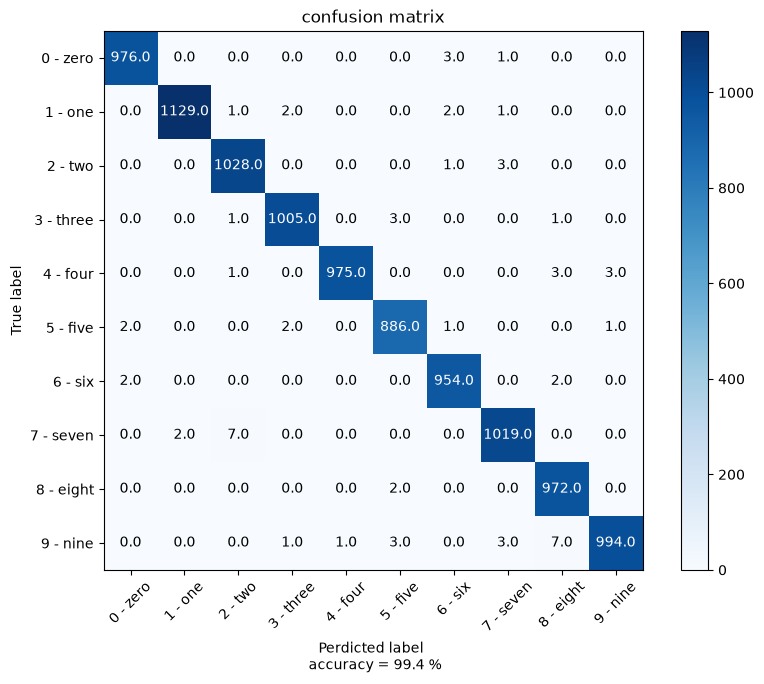

In [31]:
confusion = get_conf(load_model, test_DL)

plot_confusion_matrix(confusion, test_DS.classes)

plt.xticks(rotation=45);

torch.Size([32, 32, 28, 28])
torch.Size([32, 64, 14, 14])
torch.Size([32, 128, 7, 7])


Text(0.5, 1.0, '8 - eight (8 - eight)')

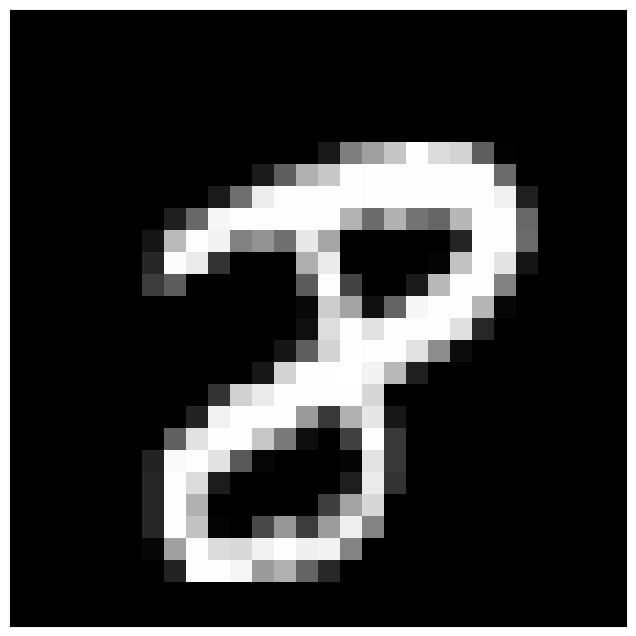

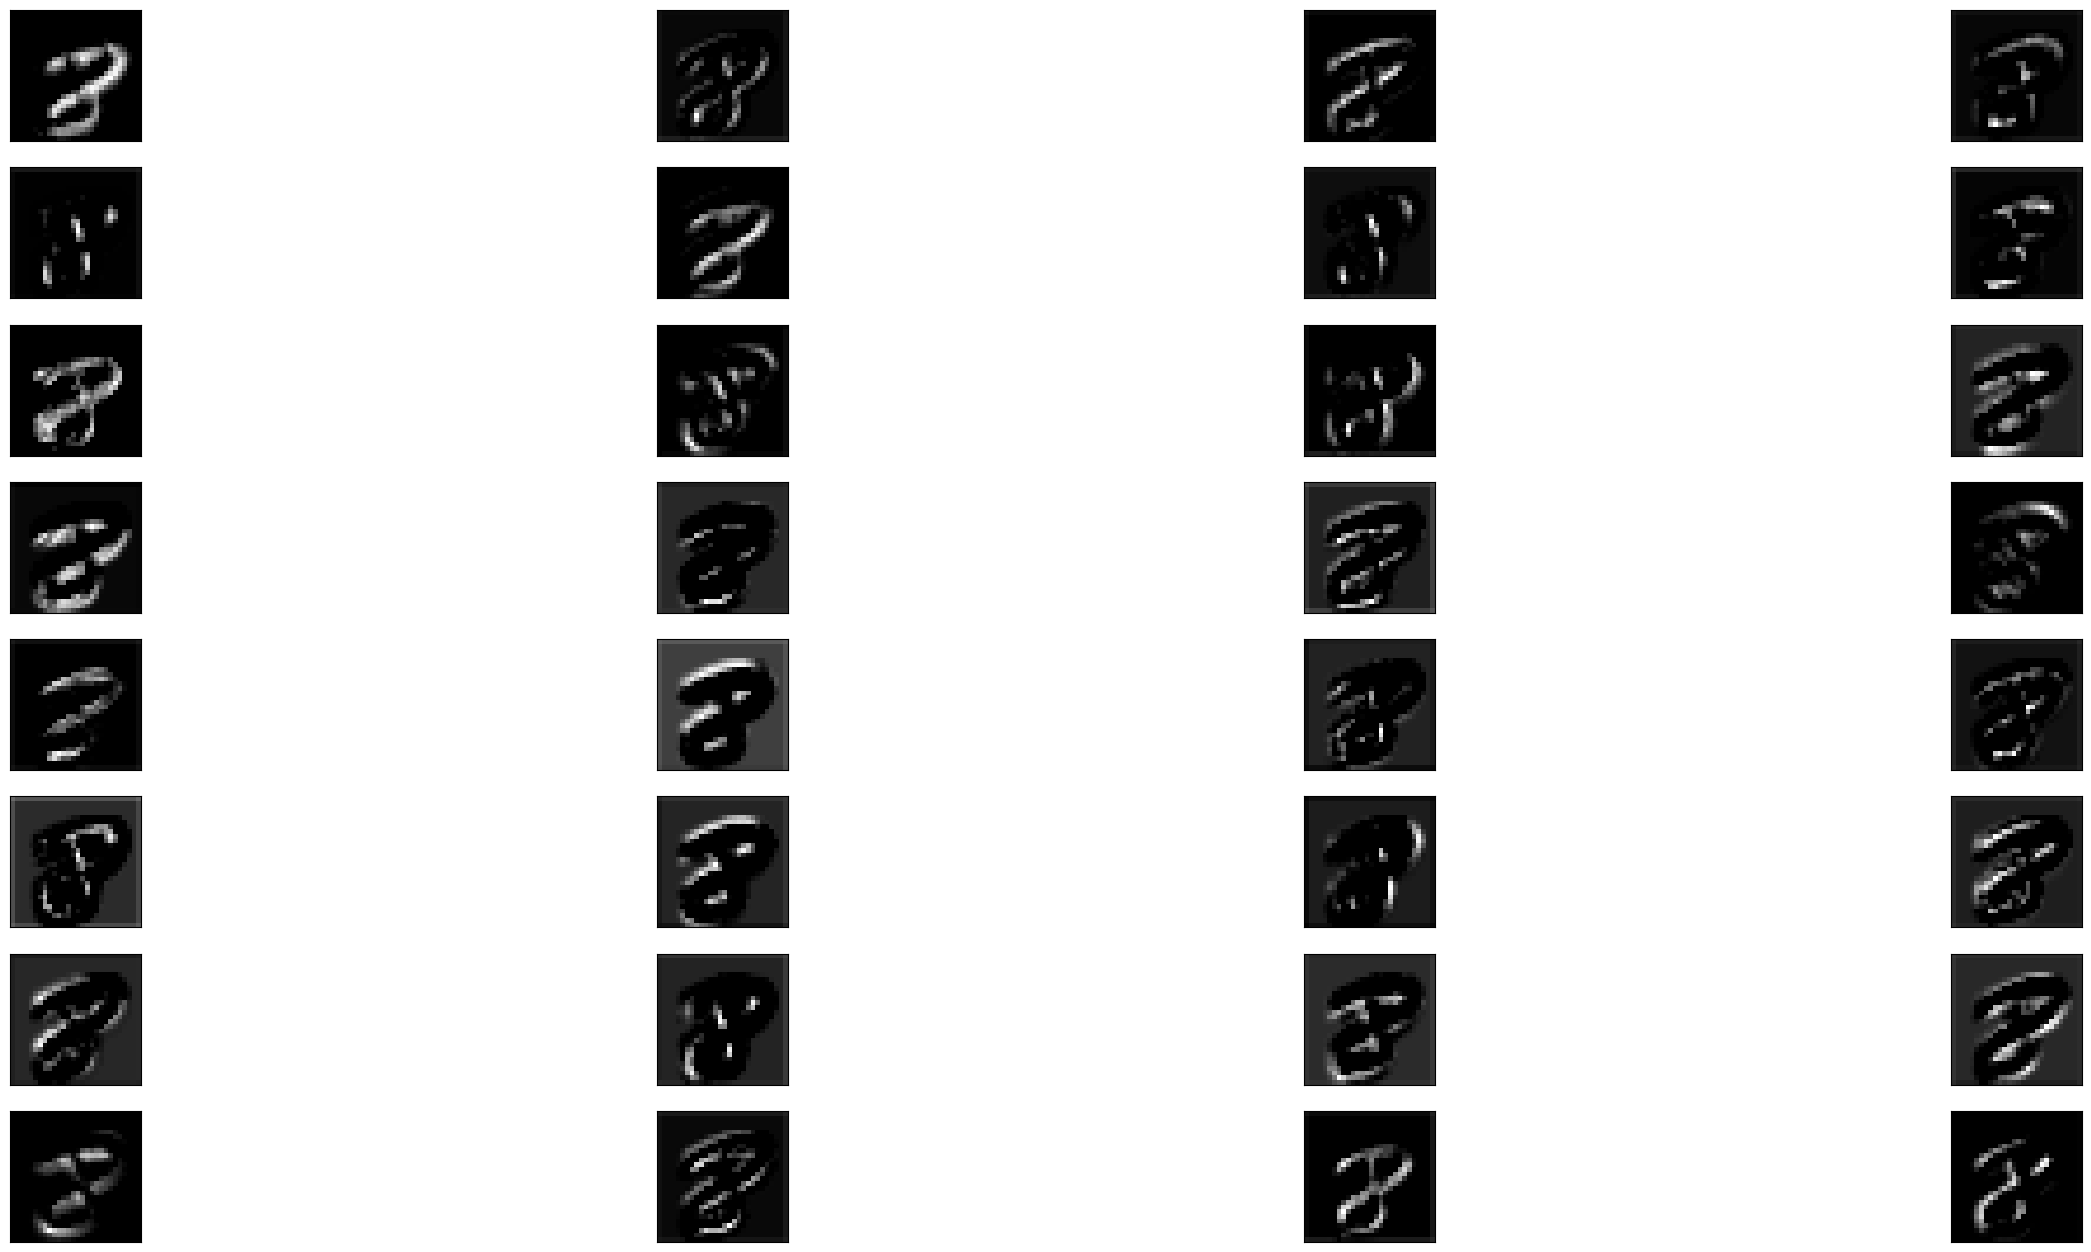

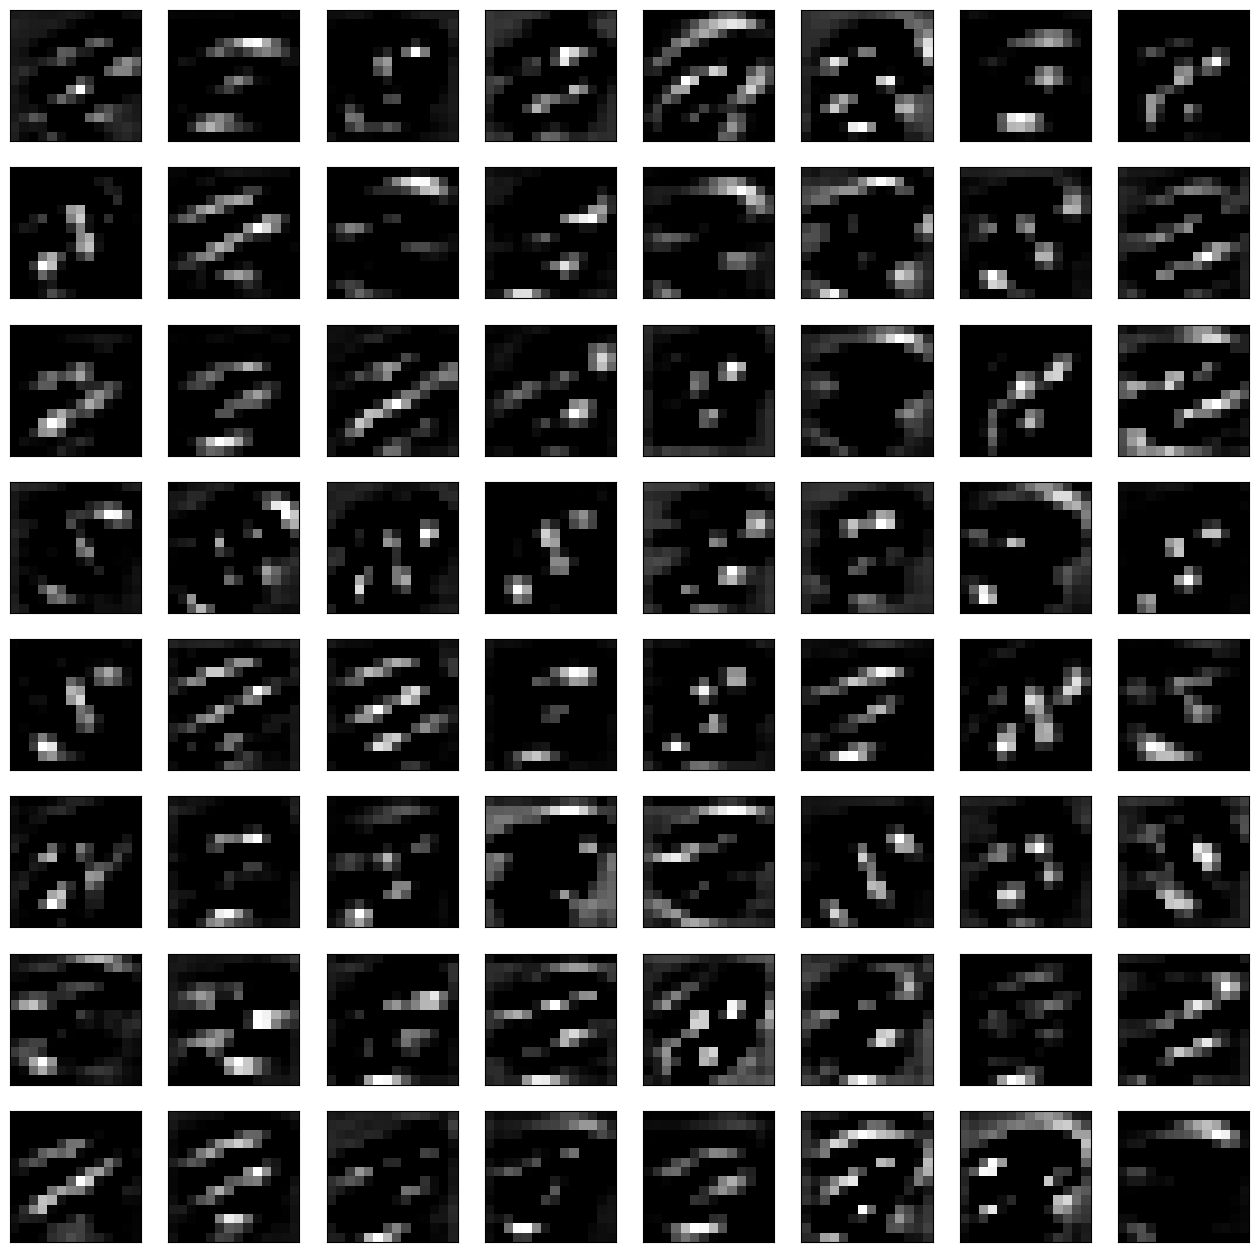

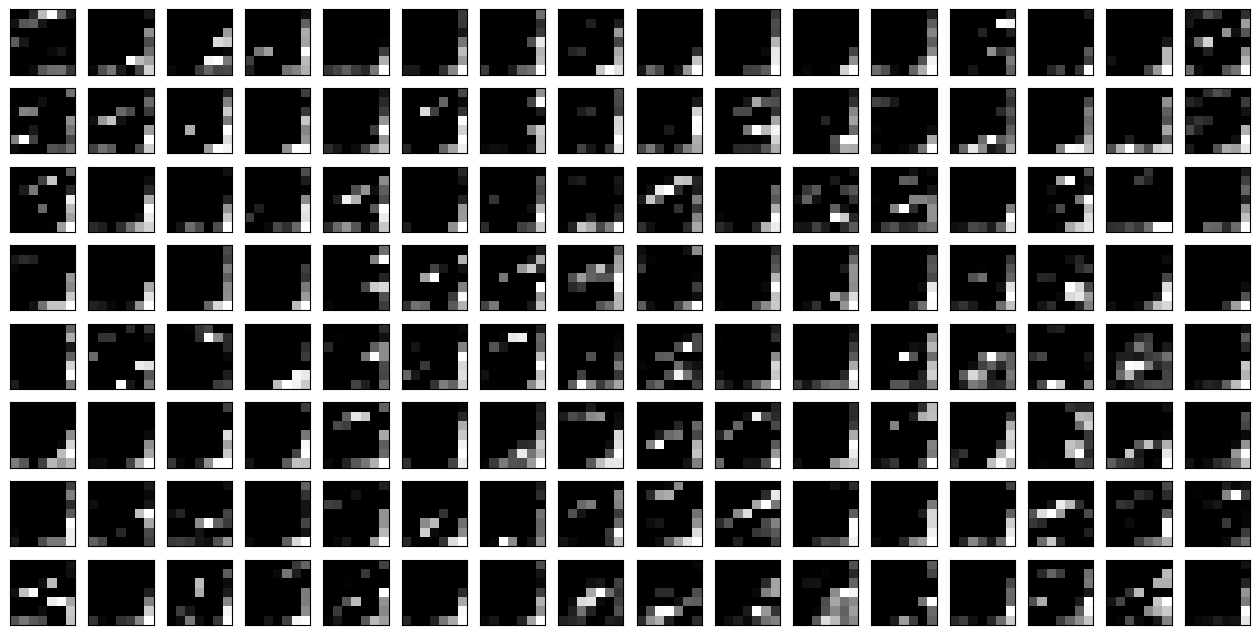

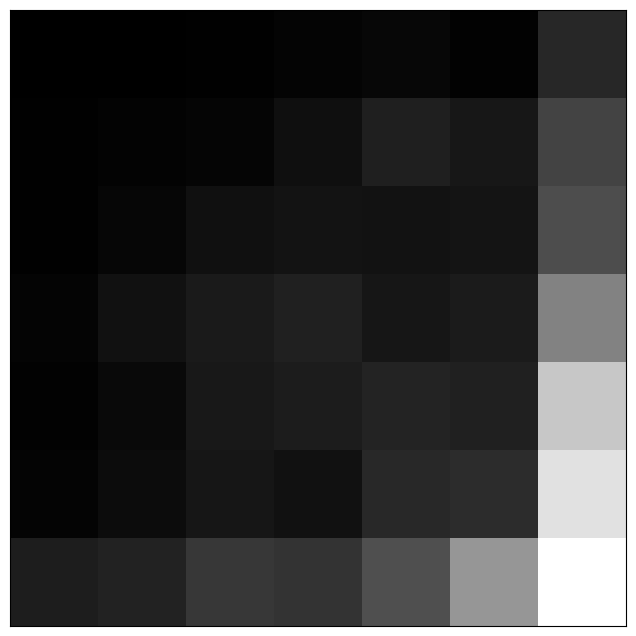

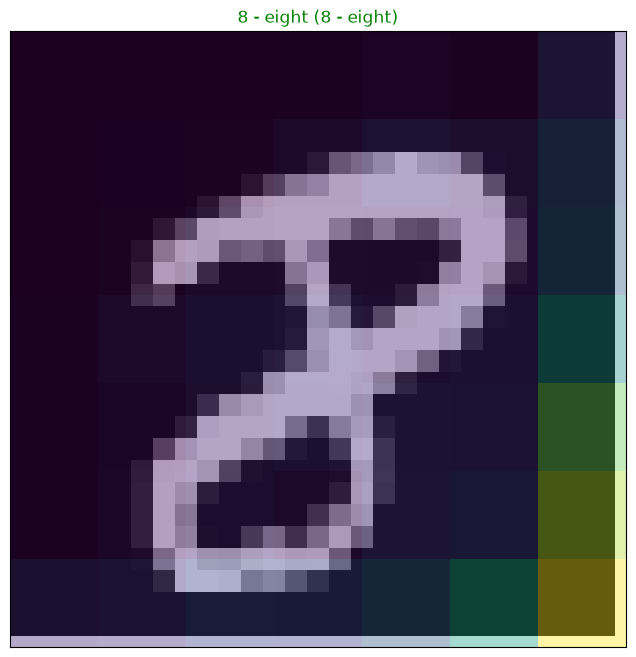

In [32]:
# feature_map : model 의 convolution 이후 틀징을 이미지화
load_model.eval()
with torch.no_grad():
    x_batch, y_batch = next(iter(test_DL))
    x_batch, y_batch = x_batch.to(device), y_batch.to(device)
    y_hat = load_model(x_batch)
    pred = y_hat.argmax(dim=1)

    # CNN
    # feature_map1 = load_model.conv1(x_batch)
    # feature_map2 = load_model.conv2(load_model.maxpool1(feature_map1))
    # feature_map3 = load_model.conv3(load_model.maxpool2(feature_map2))
    
    # CNN_deep
    feature_map1 = load_model.conv_block1(x_batch)
    feature_map2 = load_model.conv_block2(load_model.maxpool1(feature_map1))
    feature_map3 = load_model.conv_block3(load_model.maxpool2(feature_map2))

x_batch = x_batch.cpu()
feature_map1 = feature_map1.cpu()
feature_map2 = feature_map2.cpu()
feature_map3 = feature_map3.cpu()

plt.figure(figsize=(8,8))
plt.xticks([])  # 눈금표시안함
plt.yticks([])
plt.imshow(x_batch[0,0], cmap= 'gray')

print(feature_map1.shape)
plt.figure(figsize=(32,16))
for idx in range(feature_map1.shape[1]):
    # convolution 이후 (32,32,28,28) 중 2번째 차원 특징을 가져오기
    plt.subplot(8,4, idx+1, xticks=[], yticks=[])
    plt.imshow(feature_map1[0,idx], cmap='gray')
    # feature_map1[0,0] 의 특징부터 feature_map[0,31]까지 보여줌

print(feature_map2.shape)
plt.figure(figsize=(16,16))
for idx in range(feature_map2.shape[1]):
    plt.subplot(8,8, idx+1, xticks=[], yticks=[])
    plt.imshow(feature_map2[0,idx], cmap='gray')

print(feature_map3.shape)
plt.figure(figsize=(16,8))
for idx in range(feature_map3.shape[1]):
    plt.subplot(8,16, idx+1, xticks=[], yticks=[])
    plt.imshow(feature_map3[0,idx], cmap='gray')

summmed_map = feature_map3.sum(dim=1)
plt.figure(figsize=(8,8))
plt.xticks([])
plt.yticks([])
plt.imshow(summmed_map[0], cmap='gray')

plt.figure(figsize=(8,8))
plt.xticks([])
plt.yticks([])
plt.imshow(x_batch[0,0], cmap='gray')
# convolution 이후의 (3,3)을 (28,28) 사이즈로 맞춤
plt.imshow(summmed_map[0], extent=[0,28,28,0], alpha=0.4, cmap='viridis')

pred_item = test_DS.classes[pred[0].item()]
true_item = test_DS.classes[y_batch[0].item()]
plt.title(f'{pred_item} ({true_item})', color='g' if pred_item == true_item else 'r')

torch.Size([1, 32, 28, 28])
torch.Size([1, 64, 14, 14])
torch.Size([1, 128, 7, 7])


Text(0.5, 1.0, '8 - eight (4 - four)')

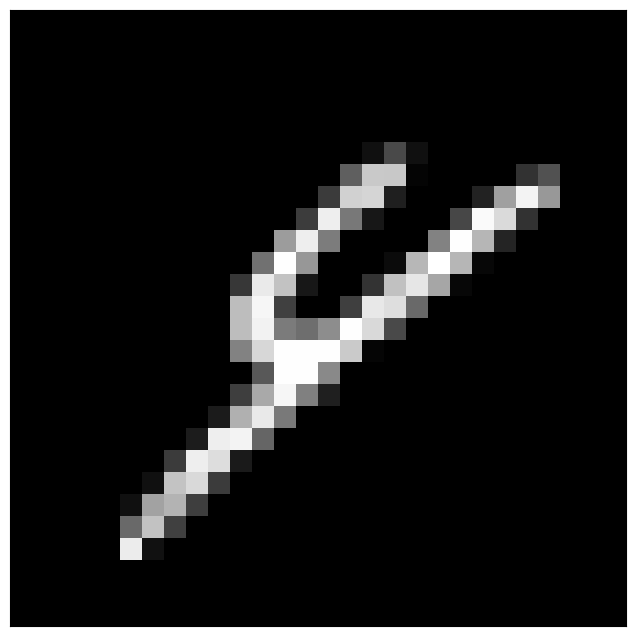

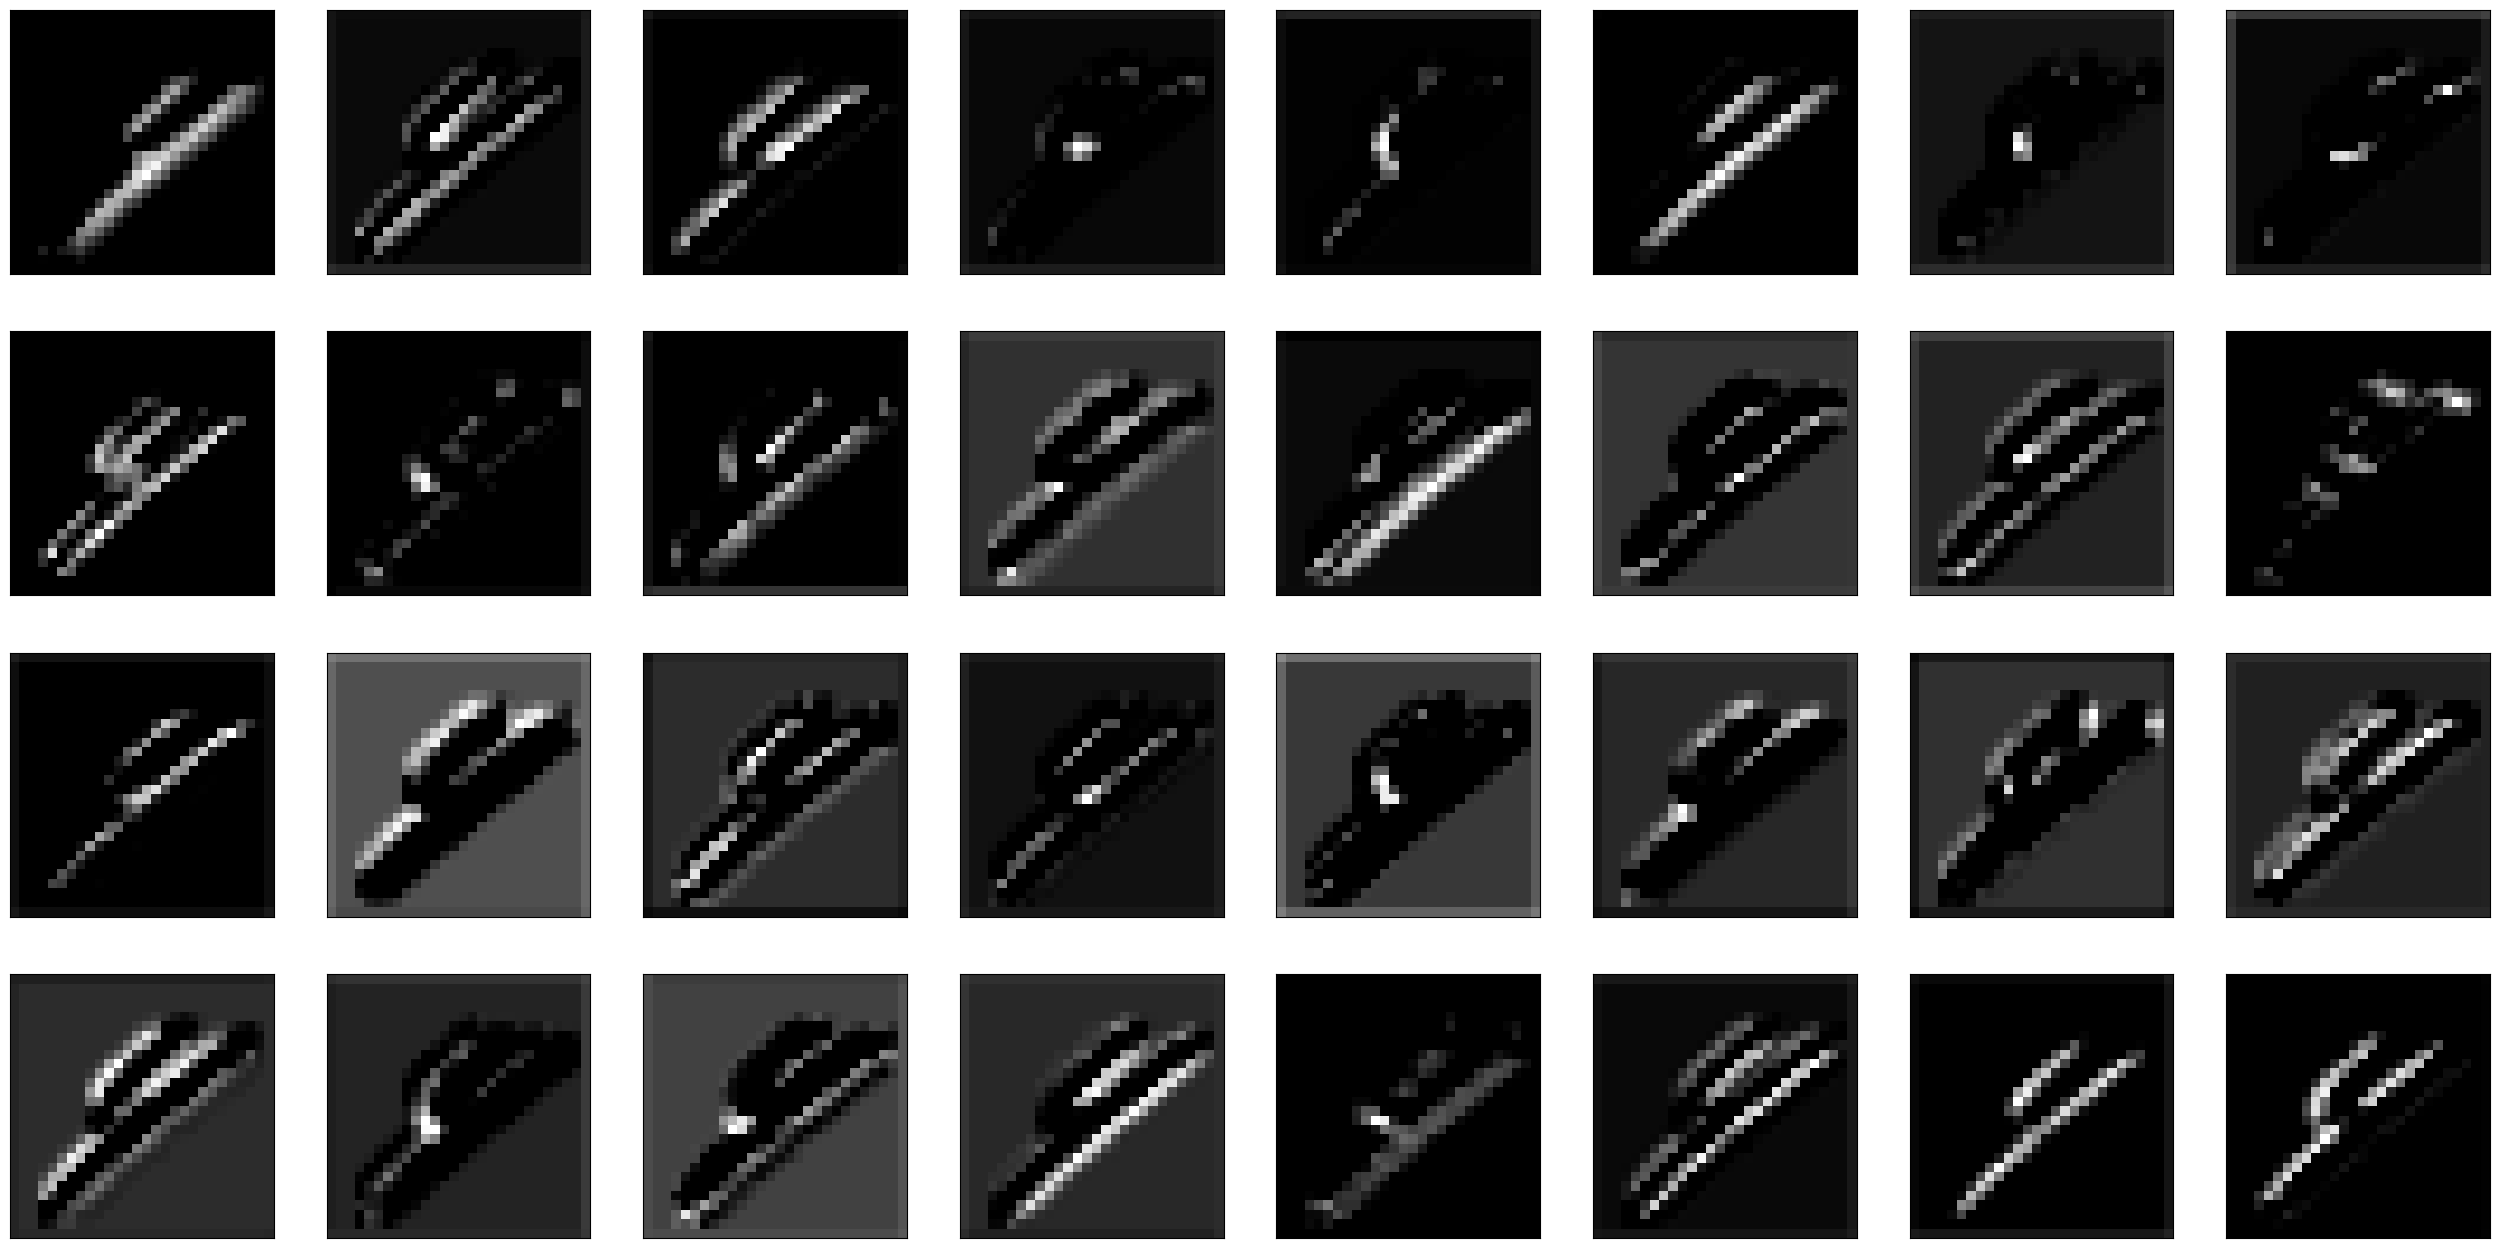

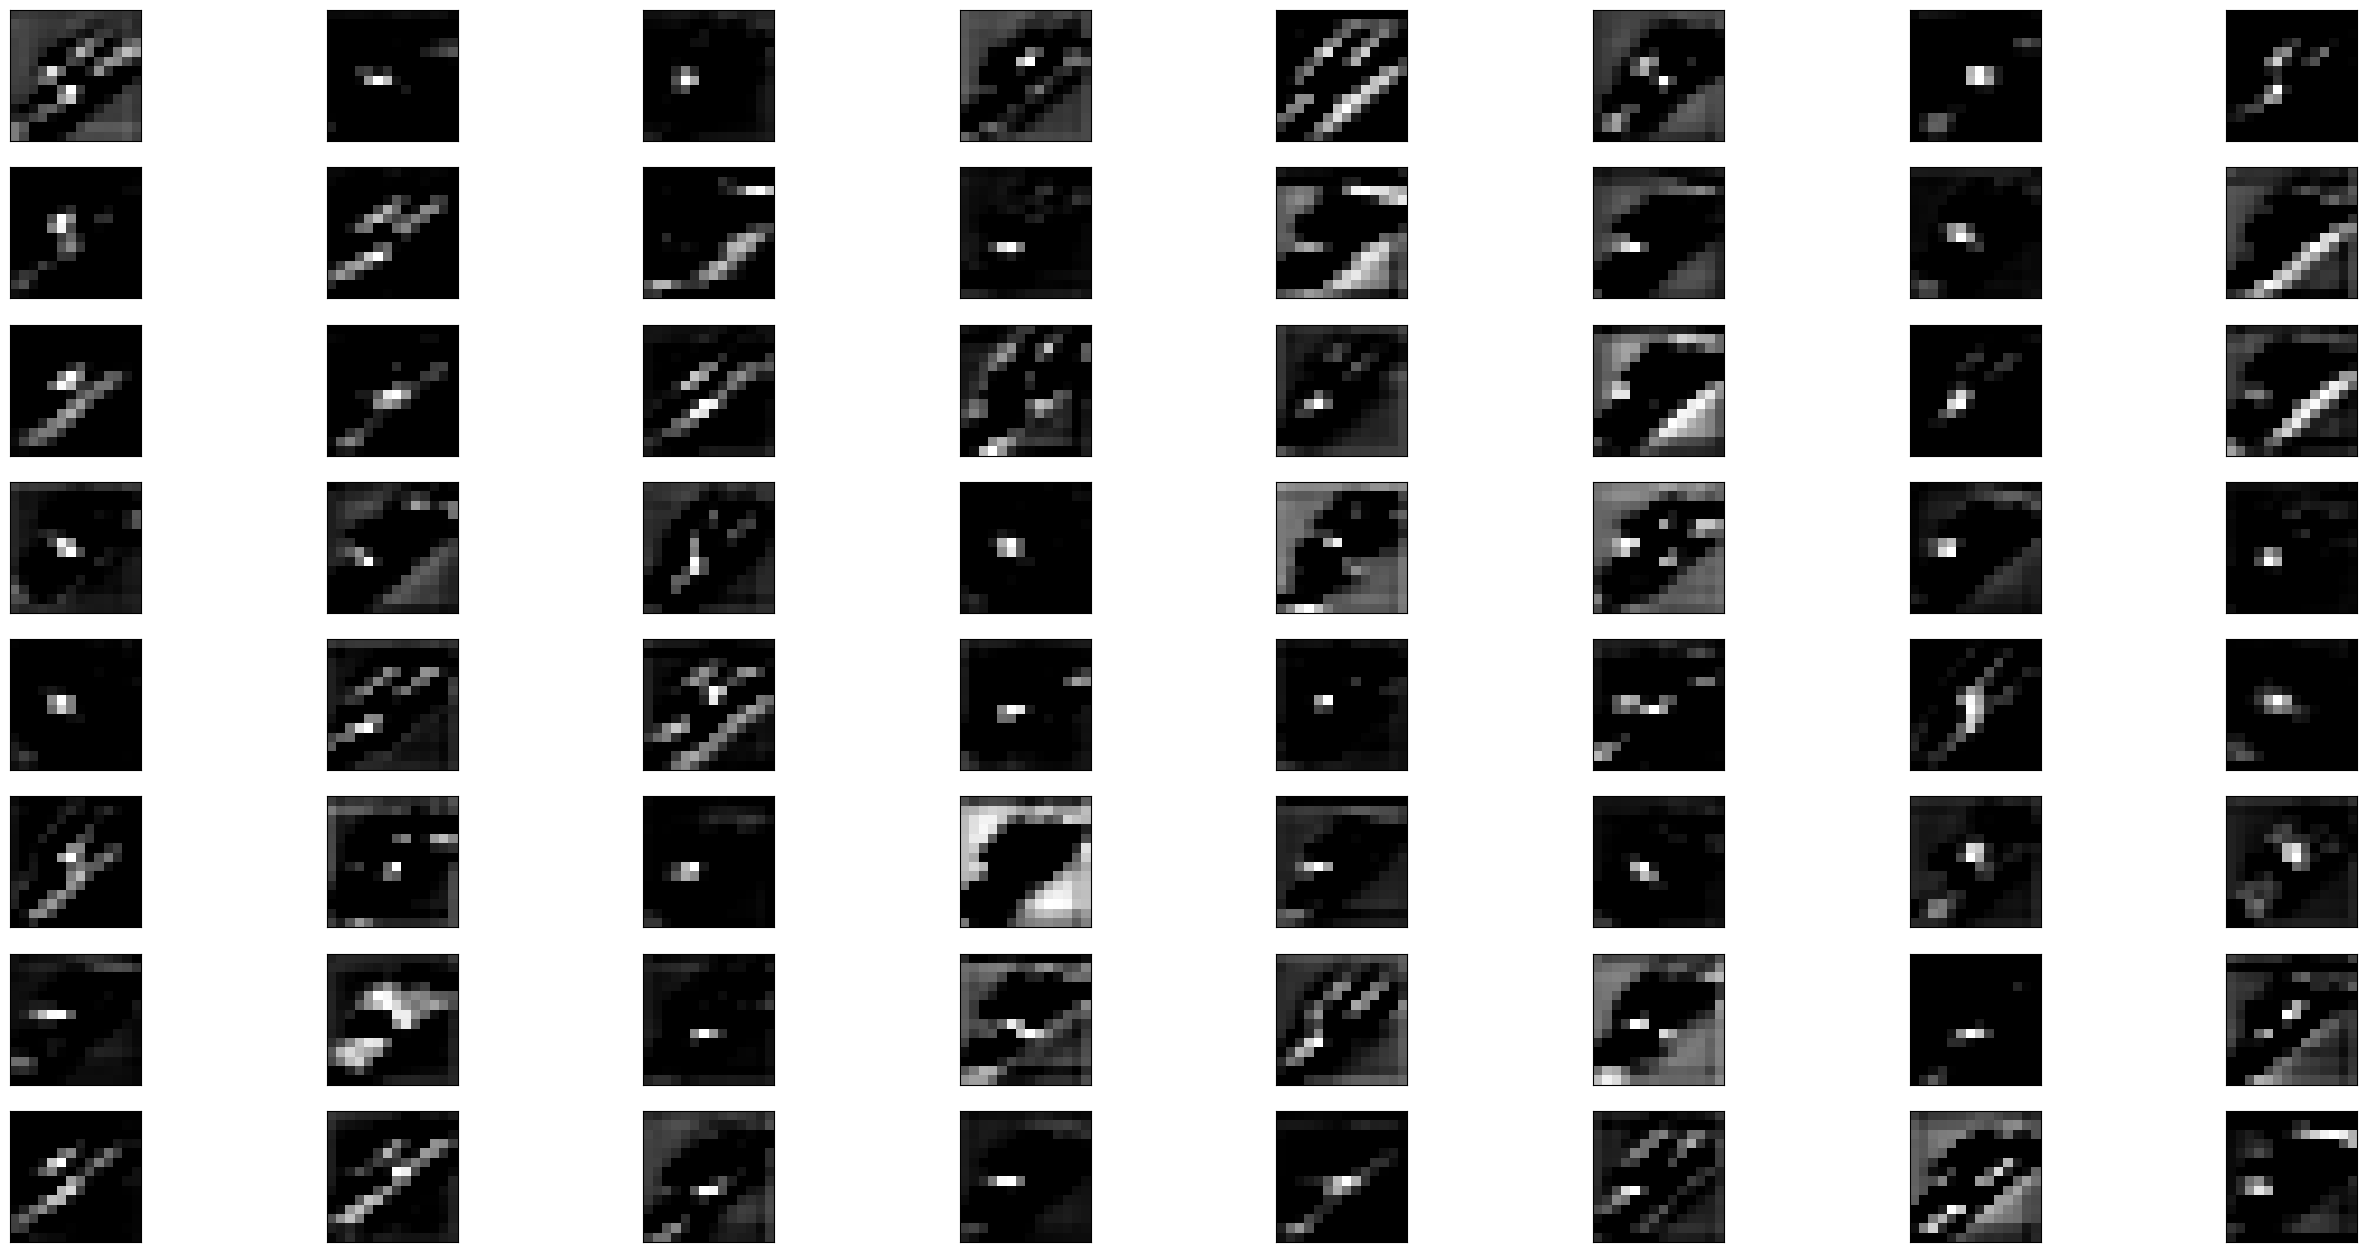

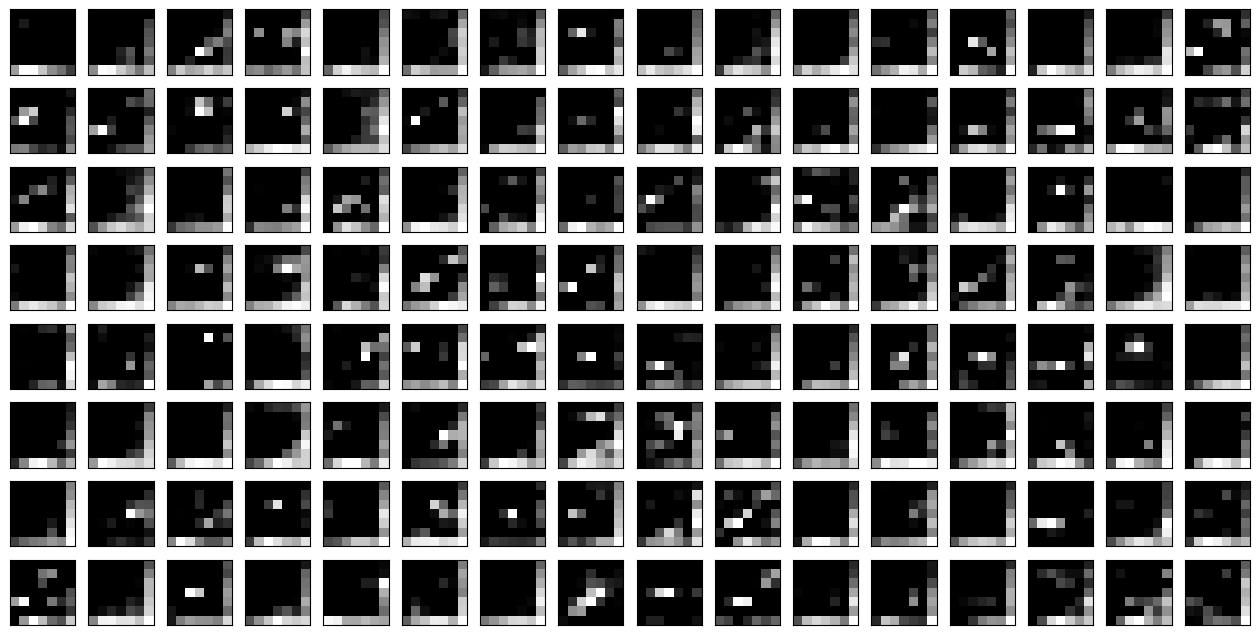

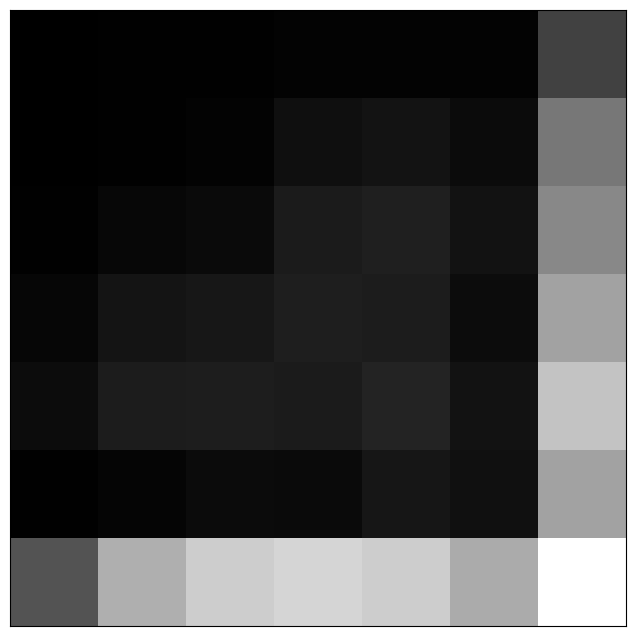

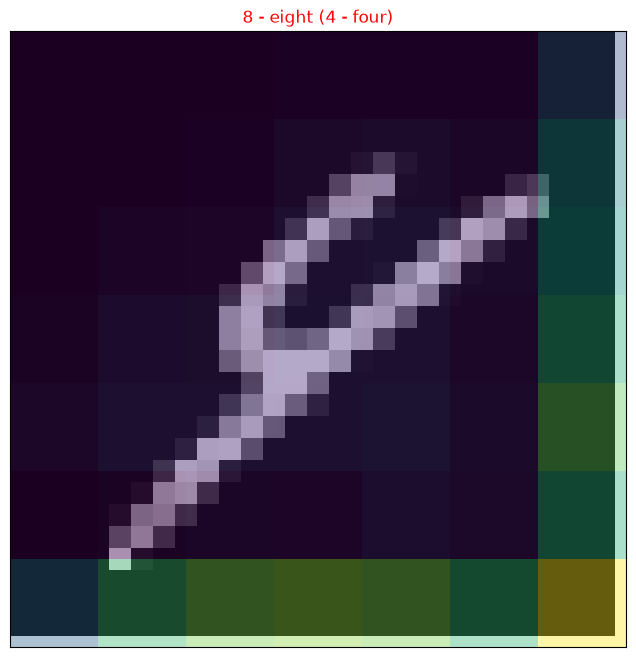

In [34]:
load_model.eval()
with torch.no_grad():
    wrong_image = None

    for x_batch, y_batch in test_DL:
        x_batch, y_batch = next(iter(test_DL))
        x_batch = x_batch.to(DEVICE)
        y_batch = y_batch.to(DEVICE)
        y_hat = load_model(x_batch)
        pred = y_hat.argmax(dim=1)

        wrong_idx = torch.where(pred != y_batch)[0]

        if len(wrong_idx) > 0 :
            idx = wrong_idx[0].item()

            wrong_image = x_batch[idx:idx+1]

            pred_label = pred[idx].item()
            true_label = y_batch[idx].item()

    if wrong_image is not None :

        # CNN 할 때 사용
        # feature_map1 = load_model.conv1(wrong_image)
        # feature_map2 = load_model.conv2(load_model.maxpool1(feature_map1))
        # feature_map3 = load_model.conv3(load_model.maxpool2(feature_map2))

        # CNN_deep 할 때 사용
        feature_map1 = load_model.conv_block1(wrong_image)
        feature_map2 = load_model.conv_block2(load_model.maxpool1(feature_map1))
        feature_map3 = load_model.conv_block3(load_model.maxpool2(feature_map2))

wrong_image = wrong_image.cpu()
feature_map1 = feature_map1.cpu()
feature_map2 = feature_map2.cpu()
feature_map3 = feature_map3.cpu()

plt.figure(figsize=(8,8))
plt.xticks([])
plt.yticks([])
plt.imshow(wrong_image[0,0], cmap='gray')

print(feature_map1.shape)
plt.figure(figsize=(32,16))
for idx in range(feature_map1.shape[1]):
    plt.subplot(4,8, idx+1, xticks=[], yticks=[])
    plt.imshow(feature_map1[0,idx], cmap='gray')

print(feature_map2.shape)
plt.figure(figsize=(32,16))
for idx in range(feature_map2.shape[1]):
    plt.subplot(8,8, idx+1, xticks=[], yticks=[])
    plt.imshow(feature_map2[0,idx], cmap='gray')

print(feature_map3.shape)
plt.figure(figsize=(16,8))
for idx in range(feature_map3.shape[1]):
    plt.subplot(8,16, idx+1, xticks=[], yticks=[])
    plt.imshow(feature_map3[0,idx], cmap='gray')

summed_map = feature_map3.sum(dim=1)
plt.figure(figsize=(8,8))
plt.xticks([])
plt.yticks([])
plt.imshow(summed_map[0], cmap='gray')

plt.figure(figsize=(8,8))
plt.xticks([])
plt.yticks([])
plt.imshow(wrong_image[0,0], cmap='gray')
plt.imshow(summed_map[0], extent=[0,28,28,0], alpha=0.4, cmap='viridis')
pred_item = test_DS.classes[pred_label]
true_item = test_DS.classes[true_label]
plt.title(f'{pred_item} ({true_item})', color='g' if pred_item == true_item else 'r')

In [ ]:
# Grad-CAM (Gradient-weighted Class Activation Mapping)
# 기존 Feature Map Sum은 모든 채널을 동일한 비중으로 합산 
# Grad-CAM은 특정 클래스의 예측 점수에 기여하는 정도를 Gradient를 이용하여 가중치로 반영
# 가중치: α

import torch.nn.functional as F

def get_gradcam(model, image, target_class=None):

    model.eval()

    image = image.to(next(model.parameters()).device)
    image = image.detach().requires_grad_(True)

    # Convolution 연산
    fm1 = model.conv_block1(image)
    fm2 = model.conv_block2(model.maxpool1(fm1))
    fm3 = model.conv_block3(model.maxpool2(fm2))

    # Fully Connected Layer
    x = model.maxpool3(fm3)
    x = torch.flatten(x, start_dim=1)
    logits = model.fc(x)

    # 예측 클래스
    pred_class = logits.argmax(dim=1).item()

    if target_class is None:
        target_class = pred_class

    # 특정 클래스의 Logit
    score = logits[0, target_class]

    # Feature Map에 대한 Gradient 계산
    gradients = torch.autograd.grad(score, fm3)[0]

    # Gradient의 공간적 평균
    weights = gradients.mean(
        dim=(2, 3),
        keepdim=True
    )

    # 채널별 중요도 반영
    cam = (weights * fm3).sum(dim=1)

    # 양의 기여도만 남김
    cam = F.relu(cam)

    # 0~1 정규화
    cam = cam - cam.min()
    cam = cam / (cam.max() + 1e-8)

    return cam[0].detach().cpu() 

In [36]:
# 모델이 오답이라고 예측한 클래스의 Grad-CAM
pred_cam = get_gradcam(
    load_model,
    wrong_image,
    target_class=pred_label
)

# 실제 정답 클래스의 Grad-CAM
true_cam = get_gradcam(
    load_model,
    wrong_image,
    target_class=true_label
)

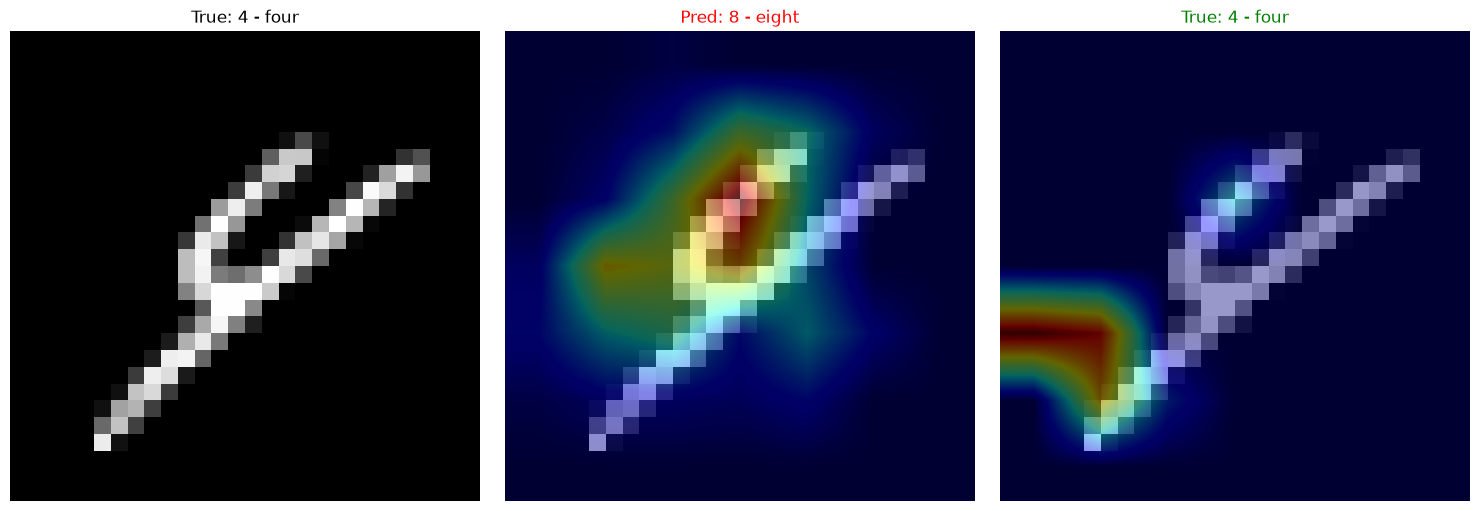

In [37]:
image = wrong_image[0, 0].cpu()

plt.figure(figsize=(15, 5))

# 원본 이미지
plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title(f'True: {test_DS.classes[true_label]}')
plt.axis('off')

# 예측 클래스 Grad-CAM
plt.subplot(1, 3, 2)
plt.imshow(image, cmap='gray', extent=[0,28,28,0])
plt.imshow(pred_cam, cmap='jet',
           extent=[0,28,28,0],
           alpha=0.4, interpolation='bilinear')
plt.title(f'Pred: {test_DS.classes[pred_label]}',
          color='r')
plt.axis('off')

# 실제 클래스 Grad-CAM
plt.subplot(1, 3, 3)
plt.imshow(image, cmap='gray', extent=[0,28,28,0])
plt.imshow(true_cam, cmap='jet',
           extent=[0,28,28,0],
           alpha=0.4, interpolation='bilinear')
plt.title(f'True: {test_DS.classes[true_label]}',
          color='g')
plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
# t - SNE  (t-distributed Stochastic Neighbor Embedding)
# Grad-CAM은 개별 이미지에 대한 분석
# t-SNE는 전체 데이터에 대해 모델이 얼마나 효과적으로 특징을 분리하고 있는지 분석
features = []
labels = []

load_model.eval()

with torch.no_grad():
    for x_batch, y_batch in test_DL:

        x_batch = x_batch.to(DEVICE)

        x = load_model.maxpool1(
            load_model.conv_block1(x_batch)
        )
        x = load_model.maxpool2(
            load_model.conv_block2(x)
        )
        x = load_model.maxpool3(
            load_model.conv_block3(x)
        )

        x = torch.flatten(x, start_dim=1)

        features.append(x.cpu())
        labels.append(y_batch.cpu())

features = torch.cat(features).numpy()
labels = torch.cat(labels).numpy()

print(features.shape)
print(labels.shape)

(10000, 1152)
(10000,)


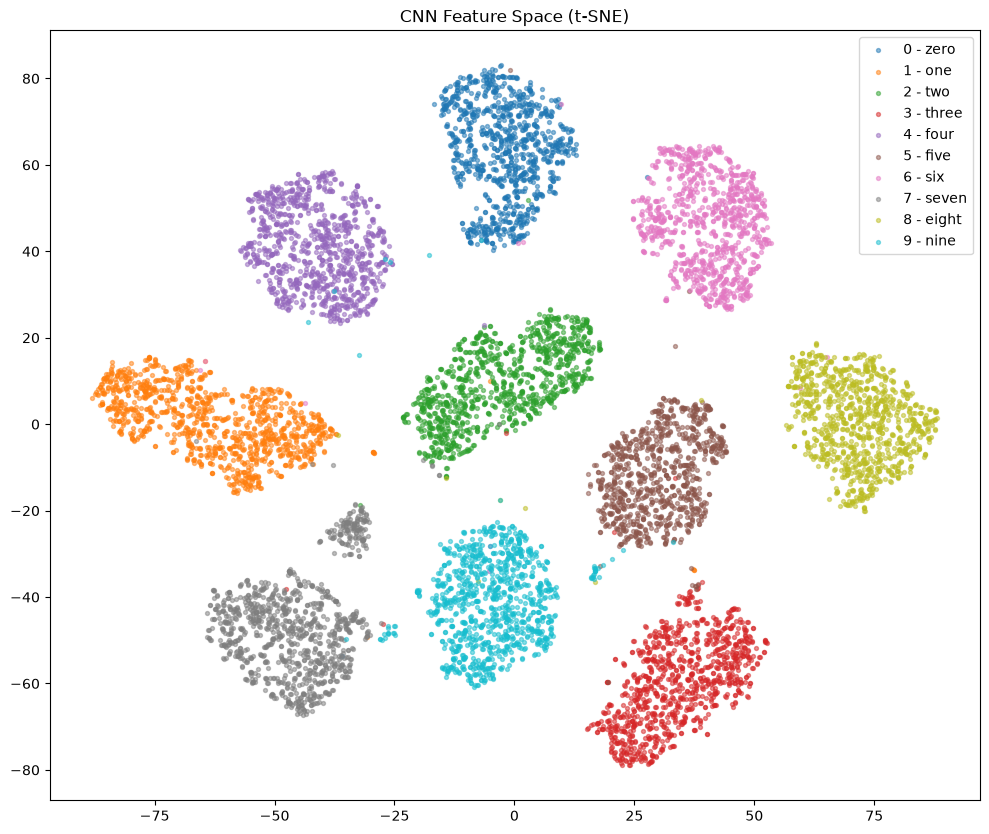

In [39]:
from sklearn.manifold import TSNE

tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42
)

features_2d = tsne.fit_transform(features)

plt.figure(figsize=(12, 10))

for idx, class_name in enumerate(test_DS.classes):

    mask = labels == idx

    plt.scatter(
        features_2d[mask, 0],
        features_2d[mask, 1],
        label=class_name,
        s=8,
        alpha=0.5
    )

plt.legend()
plt.title('CNN Feature Space (t-SNE)')
plt.show()